# Семестровая работа по введению в Машинное обучение
## Задача №2: Классификация
### Выполнил Цвиль Павел, группа ФИТ-231

## Задание:

Возьмите набор данных согласно своему варианту
(https://cloud.mail.ru/public/MWZh/DQkbAHKmi). Датасет представляет собой набор
признаков, в последнем столбце указан класс объекта.
1. Проведите предварительный анализ и подготовку данных, обработайте
пропущенные значения.
2. Проведите статистический анализ, оцените корреляции между признаками, оцените
возможные выбросы в данных, постройте поясняющие графики. Удалите из
рассмотрения признаки, которые не влияют на целевой.
3. Разбейте выборку на тренировочные и тестовые данные (60% на 40%).
4. Для предсказания класса постройте две модели, используя библиотеку sklearn:
a. Случайный лес RandomForestClassifier()
b. Метод ближайших соседей KNeighborsClassifier()
5. Для каждой модели попытайтесь добиться наилучшего возможного результата
предсказания.
6. Оцените качество работы моделей. Выведите метрики модели. Напишите какая
модель дала наилучший результат. 

### План работы
1. Загрузка и первичный анализ
2. Обработка пропусков
3. Корреляции и выбросы
4. Отбор признаков
5. Разбиение train/test (60/40)
6. Модели: RandomForest, KNN
7. Подбор гиперпараметров
8. Оценка и выводы

## 1. Загрузка данных

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Настройки
pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')

# Загрузка
df_class = pd.read_csv('data/dataset_var8_class.csv', sep=';', header=None)
df_class.columns = [f'f{i}' for i in range(df_class.shape[1] - 1)] + ['y']

print('Размер датасета:', df_class.shape)
print('\nПервые 5 строк:')
df_class.head()

Размер датасета: (100, 8)

Первые 5 строк:


,f0,f1,f2,f3,f4,f5,f6,y
0,-0.624062,0.778513,-0.034999,1.668018,-0.613678,1.209992,1.668018,2
1,-0.212489,-1.690497,0.476216,-0.285705,-2.012242,-2.266745,-0.285705,1
2,2.186700,-0.965655,1.686778,-1.729750,4.895443,2.373926,-1.729750,0
3,-0.533210,-1.843536,-0.192996,2.862843,-1.716288,1.066370,2.862843,2
4,-1.155205,0.909580,-0.722481,1.929296,-1.618793,6.337379,1.929296,2


## 2. Обработка пропусков

In [2]:
# Смотрим пропуски
print('Доля пропусков:')
print(df_class.isna().mean()[df_class.isna().mean() > 0].round(3))

# Заполняем медианой
df_class = df_class.fillna(df_class.median())

print('\nОсталось пропусков:', df_class.isna().sum().sum())
print('Размер датасета:', df_class.shape)

Доля пропусков:
f0    0.05
f1    0.05
dtype: float64

Осталось пропусков: 0
Размер датасета: (100, 8)


## 3. Статистический анализ

Построим матрицу корреляций, чтобы понять, какие признаки связаны между собой, и посмотрим на распределение классов (сколько объектов каждого класса).

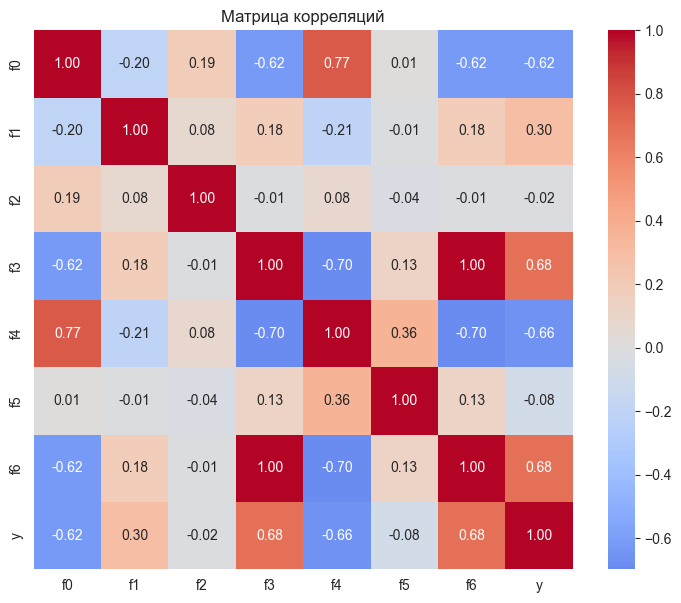

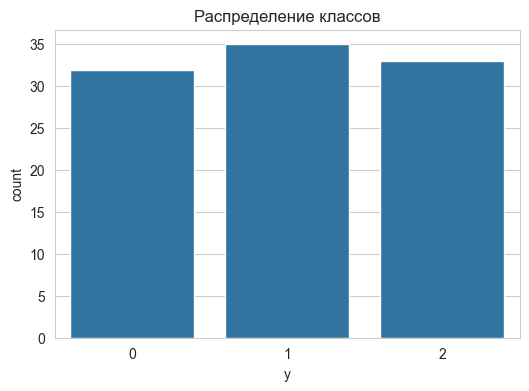

Количество объектов по классам:
y
1    35
2    33
0    32
Name: count, dtype: int64


In [3]:
# Матрица корреляций
plt.figure(figsize=(9, 7))
sns.heatmap(df_class.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True)
plt.title('Матрица корреляций')
plt.show()

# Распределение целевого класса
plt.figure(figsize=(6, 4))
sns.countplot(x='y', data=df_class)
plt.title('Распределение классов')
plt.show()

print('Количество объектов по классам:')
print(df_class['y'].value_counts())

**Вывод по корреляциям:** 

Признаки `f3` и `f6` имеют корреляцию 1.00 (полные дубликаты). Оставляем `f3`, так как он имеет более высокую корреляцию с целевой переменной `y` (0.68), а `f6` дублирует его.

## 4.1. Анализ выбросов и отбор признаков

Оценим выбросы по методу IQR. Если признак имеет очень высокую корреляцию с другим признаком (мультиколлинеарность) или не несет информации, мы можем его удалить. Но для начала просто построим boxplot.

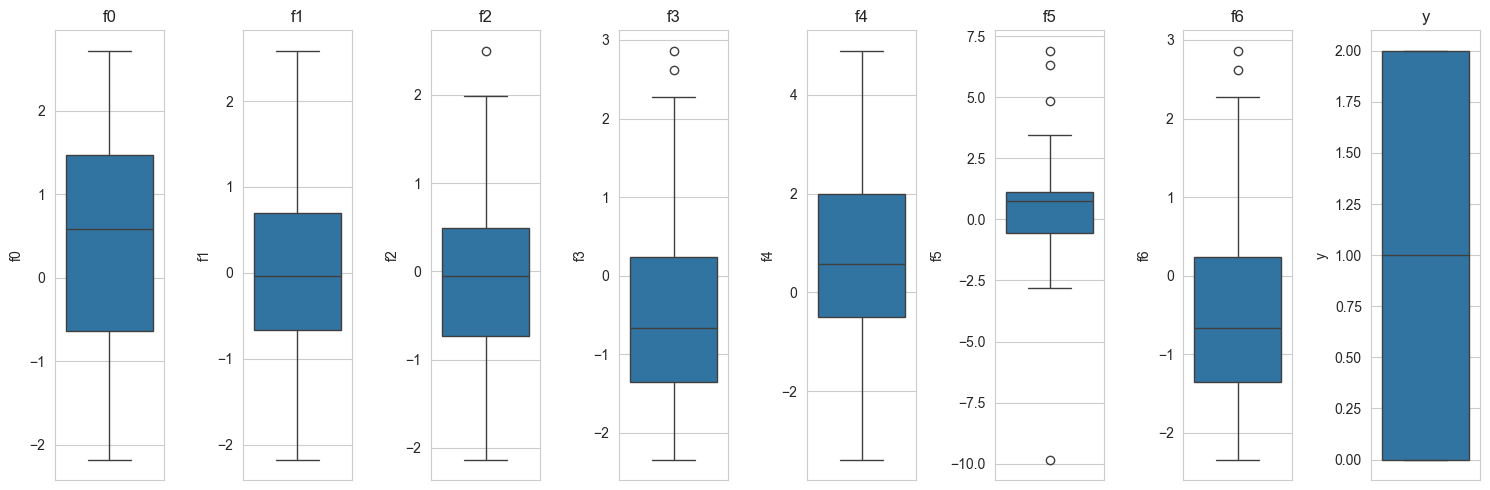

In [4]:
# Boxplot для всех признаков
fig, axes = plt.subplots(1, len(df_class.columns), figsize=(15, 5))
for ax, col in zip(axes, df_class.columns):
    sns.boxplot(y=df_class[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

### 4.2. Удаление неинформативного признака

На основе проведенного ранее корреляционного анализа (п.3) удаляем признак `f6`, так как он полностью дублирует признак `f3` (корреляция 1.00) и не несет новой информации для модели.

In [7]:
# Удаляем f6
df_class = df_class.drop(columns=['f6'])

print('Размер датасета после удаления f6:', df_class.shape)
print('Оставшиеся столбцы:', list(df_class.columns))

Размер датасета после удаления f6: (100, 7)
Оставшиеся столбцы: ['f0', 'f1', 'f2', 'f3', 'f4', 'f5', 'y']


## 5. Разбиение данных на train и test

Отделяем признаки `X` от целевой переменной `y`. Делим данные на тренировочную (60%) и тестовую (40%) выборки. Используем `stratify=y`, чтобы сохранить пропорции классов в обеих выборках (так как у нас многоклассовая задача).

In [8]:
from sklearn.model_selection import train_test_split

# Отделяем признаки от цели
X_class = df_class.drop(columns=['y'])
y_class = df_class['y']

# Разбиваем с сохранением пропорций классов (stratify)
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_class, y_class, test_size=0.4, random_state=42, stratify=y_class
)

print('Размер X_train:', X_train_c.shape)
print('Размер X_test:', X_test_c.shape)
print('Размер y_train:', y_train_c.shape)
print('Размер y_test:', y_test_c.shape)

Размер X_train: (60, 6)
Размер X_test: (40, 6)
Размер y_train: (60,)
Размер y_test: (40,)


## 6.1. Масштабирование признаков

Для метода ближайших соседей (KNN) важно привести признаки к единому масштабу, так как он чувствителен к расстояниям. Для RandomForest масштабирование не требуется, поэтому для него мы будем использовать исходные данные.

In [9]:
from sklearn.preprocessing import StandardScaler

# Масштабируем данные (будем использовать только для KNN)
scaler = StandardScaler()
X_train_scaled_c = scaler.fit_transform(X_train_c)
X_test_scaled_c = scaler.transform(X_test_c)

print('Масштабирование выполнено.')

Масштабирование выполнено.


## 6.2. Модель 1: RandomForestClassifier

Случайный лес для классификации. Обучаем на исходных (немаштабированных) данных.

In [10]:
from sklearn.ensemble import RandomForestClassifier

# Обучаем RandomForest
rf_class = RandomForestClassifier(random_state=42)
rf_class.fit(X_train_c, y_train_c)

# Оцениваем точность (Accuracy)
score_rf_c = rf_class.score(X_test_c, y_test_c)
print(f'Accuracy для RandomForest: {score_rf_c:.4f}')

Accuracy для RandomForest: 0.8000


## 6.3. Модель 2: KNeighborsClassifier

Метод ближайших соседей для классификации. Обучаем на масштабированных данных.

In [11]:
from sklearn.neighbors import KNeighborsClassifier

# Обучаем KNN
knn_class = KNeighborsClassifier()
knn_class.fit(X_train_scaled_c, y_train_c)

# Оцениваем точность
score_knn_c = knn_class.score(X_test_scaled_c, y_test_c)
print(f'Accuracy для KNeighbors: {score_knn_c:.4f}')

Accuracy для KNeighbors: 0.7250


## 7. Подбор гиперпараметров

Для улучшения качества моделей используем GridSearchCV. Переберем различные комбинации гиперпараметров для RandomForest и KNN, оценивая их с помощью кросс-валидации (cv=3).

In [12]:
from sklearn.model_selection import GridSearchCV
import warnings
warnings.filterwarnings('ignore')

# 1. RandomForest
param_grid_rf_c = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 5, 10]
}
grid_rf_c = GridSearchCV(RandomForestClassifier(random_state=42), param_grid_rf_c, cv=3, scoring='accuracy')
grid_rf_c.fit(X_train_c, y_train_c)
print(f'Лучшие параметры RF: {grid_rf_c.best_params_}')
print(f'Лучший Accuracy (CV) для RF: {grid_rf_c.best_score_:.4f}\n')

# 2. KNN
param_grid_knn_c = {
    'n_neighbors': [3, 5, 7, 9],
    'weights': ['uniform', 'distance']
}
grid_knn_c = GridSearchCV(KNeighborsClassifier(), param_grid_knn_c, cv=3, scoring='accuracy')
grid_knn_c.fit(X_train_scaled_c, y_train_c)
print(f'Лучшие параметры KNN: {grid_knn_c.best_params_}')
print(f'Лучший Accuracy (CV) для KNN: {grid_knn_c.best_score_:.4f}\n')

Лучшие параметры RF: {'max_depth': None, 'n_estimators': 200}
Лучший Accuracy (CV) для RF: 0.9000

Лучшие параметры KNN: {'n_neighbors': 5, 'weights': 'distance'}
Лучший Accuracy (CV) для KNN: 0.8167



## 8. Финальная оценка моделей

Обучаем финальные версии моделей с лучшими гиперпараметрами, найденными с помощью GridSearchCV. Выводим метрики качества: Accuracy (доля правильных ответов), Precision (точность), Recall (полнота) и F1-score (гармоническое среднее между ними).

In [14]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 1. RandomForest с лучшими параметрами
rf_final_c = RandomForestClassifier(random_state=42, **grid_rf_c.best_params_)
rf_final_c.fit(X_train_c, y_train_c)
y_pred_rf = rf_final_c.predict(X_test_c)

# 2. KNN с лучшими параметрами
knn_final_c = KNeighborsClassifier(**grid_knn_c.best_params_)
knn_final_c.fit(X_train_scaled_c, y_train_c)
y_pred_knn = knn_final_c.predict(X_test_scaled_c)

# Выводим метрики для RandomForest
print("=== Оценка RandomForestClassifier ===")
print(f"Accuracy: {accuracy_score(y_test_c, y_pred_rf):.4f}")
print("\nClassification Report:")
print(classification_report(y_test_c, y_pred_rf))

# Выводим метрики для KNN
print("\nОценка KNeighborsClassifier")
print(f"Accuracy: {accuracy_score(y_test_c, y_pred_knn):.4f}")
print("\nClassification Report:")
print(classification_report(y_test_c, y_pred_knn))

# Сравнение лучшей модели
best_class_model = 'RandomForest' if accuracy_score(y_test_c, y_pred_rf) > accuracy_score(y_test_c, y_pred_knn) else 'KNeighbors'
best_acc = max(accuracy_score(y_test_c, y_pred_rf), accuracy_score(y_test_c, y_pred_knn))
print(f"\nЛучшая модель классификации: {best_class_model} с Accuracy = {best_acc:.4f}")

=== Оценка RandomForestClassifier ===
Accuracy: 0.8000

Classification Report:
              precision    recall  f1-score   support

           0       0.69      0.69      0.69        13
           1       0.85      0.79      0.81        14
           2       0.86      0.92      0.89        13

    accuracy                           0.80        40
   macro avg       0.80      0.80      0.80        40
weighted avg       0.80      0.80      0.80        40


Оценка KNeighborsClassifier
Accuracy: 0.7250

Classification Report:
              precision    recall  f1-score   support

           0       0.60      0.46      0.52        13
           1       0.62      0.71      0.67        14
           2       0.93      1.00      0.96        13

    accuracy                           0.72        40
   macro avg       0.72      0.73      0.72        40
weighted avg       0.72      0.72      0.72        40


Лучшая модель классификации: RandomForest с Accuracy = 0.8000


## 9. Важность признаков и итоговый вывод

Лучшей моделью классификации оказался RandomForestClassifier (Accuracy = 0.8000). Выведем важность признаков (`feature_importances_`), чтобы понять, какие из них внесли наибольший вклад в предсказание класса.

Важность признаков (RandomForestClassifier):
f5    0.3209
f4    0.2093
f0    0.1852
f3    0.1777
f1    0.0553
f2    0.0516
dtype: float64


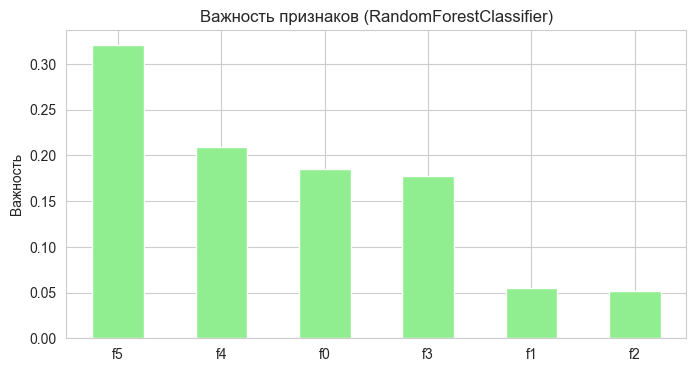

In [17]:
# Вывод важности признаков для лучшей модели (RandomForest)
importances_class = pd.Series(rf_final_c.feature_importances_, index=X_class.columns).sort_values(ascending=False)
print("Важность признаков (RandomForestClassifier):")
print(importances_class.round(4))

plt.figure(figsize=(8, 4))
importances_class.plot(kind='bar', color='lightgreen')
plt.title('Важность признаков (RandomForestClassifier)')
plt.ylabel('Важность')
plt.xticks(rotation=0)
plt.show()


## 10. Общий вывод по задаче классификации

В ходе выполнения второй части семестровой работы были решены следующие задачи:

1. **Подготовка данных:** Проведен предварительный анализ, пропуски заполнены медианой. Построены графики (boxplot, матрица корреляций, распределение классов).
2. **Отбор признаков:** Обнаружена мультиколлинеарность — признаки `f3` и `f6` оказались полными дубликатами (корреляция 1.00). Признак `f6` был удален.
3. **Разбиение и масштабирование:** Данные разделены на train (60%) и test (40%) со стратификацией. Для KNN применено масштабирование (`StandardScaler`).
4. **Обучение моделей:** Обучены две модели: `RandomForestClassifier` и `KNeighborsClassifier`.
5. **Подбор гиперпараметров:** С помощью `GridSearchCV` подобраны оптимальные параметры. Для RandomForest лучшим оказалось 200 деревьев без ограничения глубины, для KNN — 5 соседей с учетом расстояния.
6. **Оценка качества:** 
   - **RandomForestClassifier:** Accuracy = **0.8000**. Модель показала лучший результат.
   - **KNeighborsClassifier:** Accuracy = **0.7250**. 
7. **Анализ важности признаков:** Выведен `feature_importances_` для лучшей модели.

**Итог:** Наилучший результат в задаче классификации показал **RandomForestClassifier (Accuracy = 0.8000)**, что подтверждает его эффективность для табличных данных с нелинейными зависимостями. Модель KNN показала результат ниже (0.7250), так как при малом размере выборки (100 строк) ей сложнее находить точных соседей.